# 01 · 量化投资与资产配置：QuantumBridge × 夸父云

        面向会基础 Python、概率和量子门的读者。本笔记可从首格运行到末格，默认不访问网络、
        不读取密钥、不产生真机任务。目标是一个可核验的小规模端到端案例，不等于该金融行业全部能力。

        数据全部为明确给定的合成数据，不是投资建议，不用于真实交易或生产风险管理。
        步骤：原理 → 输入与经典参考 → 电路与中间结果 → 本地实际采样 → 云任务与结果 → 最终比较。

In [1]:
from pathlib import Path
import json, os, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'quantumbridge').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Run this notebook from inside the QuantumBridge repository')
sys.path.insert(0, str(ROOT))
from quantumbridge.finance import build_finance_cases, run_local, FinanceCloudSession
from quantumbridge.finance.execution import circuit_artifact
from quantumbridge.finance.kernels import labels
from quantumbridge.devices import StatevectorDevice
import html
def pretty(value):
    print(json.dumps(value, ensure_ascii=False, indent=2))
def display_table(rows, fields):
    table = '<table><thead><tr>' + ''.join('<th>' + html.escape(f) + '</th>' for f in fields) + '</tr></thead><tbody>'
    for row in rows:
        table += '<tr>' + ''.join('<td>' + html.escape(str(row[f])) + '</td>' for f in fields) + '</tr>'
    display(HTML(table + '</tbody></table>'))
case = build_finance_cases()['allocation']
if os.environ.get('QB_FINANCE_REPLAY_HARDWARE') == '1':
    from quantumbridge.finance.acceptance import restore_submitted_circuits
    case = restore_submitted_circuits(case, ROOT / 'output' / 'finance-hardware' / 'session.json')
    print('Using EXACT originally submitted QASM; strict plan/receipt hashes retained.')
print('Case:', case.key, '| quantum circuits:', len(case.experiments))
print('Result labels use q0-first ordering. Cloud ordering is calibrated separately.')

Using EXACT originally submitted QASM; strict plan/receipt hashes retained.
Case: allocation | quantum circuits: 1
Result labels use q0-first ordering. Cloud ordering is calibrated separately.


## 1. 原理：均值—方差组合、QUBO 与 QAOA

四个合成资产各用一个比特 $x_i\in\{0,1\}$ 表示是否持有，固定持有两个资产。
最小化 $f(x)=q x^T\Sigma x-\mu^T x$。这里是二元选择，不是连续权重优化，
收益率和协方差统一采用年化量纲。协方差是对称正定的人工输入。

将约束并入 $C(x)=f(x)+\lambda(\sum_i x_i-2)^2$，穷举16种组合仅用于小规模
**经典正确性对照**，不把已知最优解制备成量子态。$x_i=(1-Z_i)/2$ 将成本变成
$Z_i$ 和 $Z_iZ_j$；程序通过成本真值表的 Walsh 系数得到相同的 Ising 展开。
一个成本层加一个混合层：
$|\psi(\gamma,\beta)\rangle=e^{-i\beta\sum_i X_i}e^{-i\gamma C(Z)}|+\rangle^{\otimes4}$。
$Z_iZ_j$ 项用 CX—RZ—CX 实现。经典本地网格搜索和细化选择角度，
**只将最终电路提交真机**，本例不是完整的硬件闭环优化。

实现步骤：输入模型 → 枚举并验证罚项 → 本地训练角度 → 编译 QASM → 测量 →
检查可行性 → 在实际测得的可行候选中选成本最低者 → 与经典最优比较。
还会显示可行概率和最优解概率，不能只展示恰好命中的一个解。

## 2. 输入模型与精确对照
先检查输入、量纲和约束，随后所有量子采样结果使用同一个模型比较。

In [2]:
pretty(case.inputs)

{
  "asset_names": [
    "Synthetic A",
    "Synthetic B",
    "Synthetic C",
    "Synthetic D"
  ],
  "expected_returns": [
    0.17,
    0.14,
    0.11,
    0.09
  ],
  "covariance": [
    [
      0.12,
      0.03,
      0.02,
      0.01
    ],
    [
      0.03,
      0.1,
      0.01,
      0.02
    ],
    [
      0.02,
      0.01,
      0.08,
      0.01
    ],
    [
      0.01,
      0.02,
      0.01,
      0.06
    ]
  ],
  "risk_factor": 0.65,
  "holdings": 2,
  "penalty": 1.6,
  "previous_selection": [
    1,
    0,
    1,
    0
  ],
  "transaction_cost_per_changed_bit": 0,
  "data_source": "fixed synthetic annualized inputs, not observed market quotes"
}


Covariance eigenvalues: [0.05012631 0.07330515 0.0827078  0.15386074]


bitstring,objective,feasible,penalized_cost
0000,0.0,False,6.4
0001,-0.051,False,1.5490000000000002
0010,-0.057999999999999996,False,1.542
0011,-0.09600000000000003,True,-0.09600000000000003
0100,-0.07500000000000001,False,1.5250000000000001
0101,-0.1,True,-0.1
0110,-0.12,True,-0.12
0111,-0.13199999999999998,False,1.4680000000000002
1000,-0.09200000000000001,False,1.508
1001,-0.13,True,-0.13


Exact feasible oracle: {'best_selection': '1001', 'best_objective': -0.13, 'feasible_count': 6, 'penalized_global_minimum_is_feasible': True, 'existing_native_exact_solver': [1, 0, 0, 1]}
Local optimizer final angles: {'evaluation': 14, 'expected_cost': 0.3712126015884654, 'gamma': 2.0356920901923448, 'beta': 2.858891680236732, 'phase': 'local-refine'}


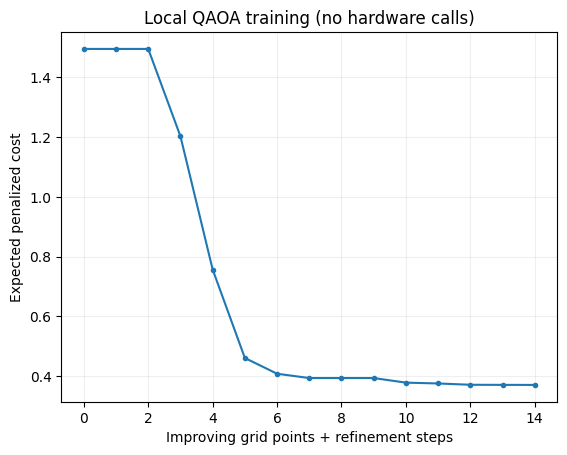

In [3]:
mu = np.array(case.inputs['expected_returns'])
sigma = np.array(case.inputs['covariance'])
print('Covariance eigenvalues:', np.linalg.eigvalsh(sigma))
assert np.linalg.eigvalsh(sigma).min() > 0
rows = case.intermediate['candidates']
display_table(rows, ['bitstring', 'objective', 'feasible', 'penalized_cost'])
print('Exact feasible oracle:', case.reference)
trace = case.intermediate['local_optimizer_trace']
print('Local optimizer final angles:', trace[-1])
plt.plot([row['expected_cost'] for row in trace], marker='.')
plt.xlabel('Improving grid points + refinement steps'); plt.ylabel('Expected penalized cost')
plt.title('Local QAOA training (no hardware calls)'); plt.grid(alpha=.2); plt.show()

## 3. 中间效果：电路、门数、理想概率

        所有实际提交门限定为 H、RY、RX、RZ、CX。概率/带符号实振幅加载在本地生成门序列，
        不是在云上执行 Python/NumPy。下格展示将提交的完整 QASM、量子比特数、双比特门数以及
        本地理想概率。真实设备的编译映射和噪声可能改变深度与分布。

In [4]:
for name, circuit in case.experiments.items():
    artifact = circuit_artifact(circuit)
    print(name, '| qubits:', artifact['num_qubits'], '| gates:', artifact['gates'],
          '| two-qubit gates:', artifact['two_qubit_gates'], '| SHA256:', artifact['sha256'])
    print(artifact['openqasm'])
    print('Ideal probabilities:', StatevectorDevice().probabilities(circuit))

qaoa | qubits: 4 | gates: 30 | two-qubit gates: 12 | SHA256: 503493d33caa8539ceaa7642045cc416e2ea8a743d80b964c43d1b421e52758c
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
h q[0];
h q[1];
h q[2];
h q[3];
rz(0.0077936144341207514) q[3];
rz(0.0099758264756745086) q[2];
cx q[2],q[3];
rz(0.50081766353660062) q[3];
cx q[2],q[3];
rz(0.01122280478513393) q[1];
cx q[1],q[3];
rz(0.50284400328947199) q[3];
cx q[1],q[3];
cx q[1],q[2];
rz(0.50081766353660062) q[2];
cx q[1],q[2];
rz(0.016522462600336012) q[0];
cx q[0],q[3];
rz(0.50081766353660062) q[3];
cx q[0],q[3];
cx q[0],q[2];
rz(0.50284400328947199) q[2];
cx q[0],q[2];
cx q[0],q[1];
rz(0.50487034304234357) q[1];
cx q[0],q[1];
rx(5.7177833604734642) q[0];
rx(5.7177833604734642) q[1];
rx(5.7177833604734642) q[2];
rx(5.7177833604734642) q[3];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];
measure q[3] -> c[3];

Ideal probabilities: {'0000': 0.008345694480299712, '0001': 0.028400342449932135, '0010': 0.02845452708810

## 4. 中间效果：1024 shots 本地实际采样
固定种子保证可重现。以下输出明确是本地模拟器，不是真机结果。

qaoa local_simulator | measured shots: 1024
Raw measured counts: {'0101': 127, '1001': 121, '1101': 37, '0011': 123, '1100': 134, '1010': 105, '0110': 118, '0100': 30, '1011': 37, '1110': 40, '0010': 36, '0001': 30, '0111': 38, '1000': 29, '1111': 10, '0000': 9}


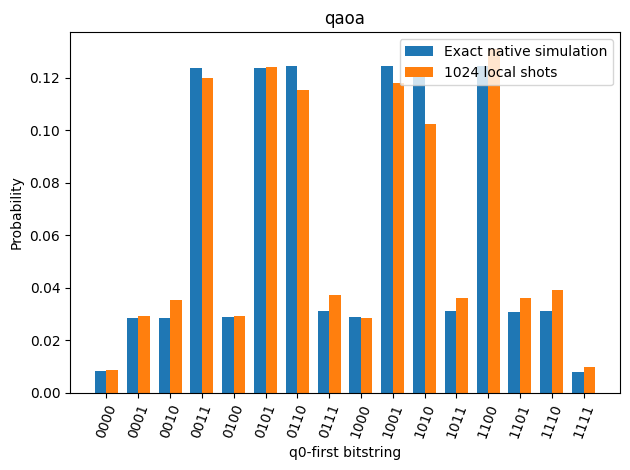

{
  "feasible_probability": 0.7109375,
  "optimal_probability": 0.1181640625,
  "expected_penalized_cost": 0.43812988281250004,
  "best_observed_feasible": {
    "bitstring": "1001",
    "selection": [
      1,
      0,
      0,
      1
    ],
    "objective": -0.13,
    "feasible": true,
    "violations": {
      "holdings": 0
    },
    "penalized_cost": -0.13
  },
  "best_observed_gap": 0.0,
  "decision_rule": "best feasible sampled candidate; not necessarily the most frequent string"
}


In [5]:
local_results = run_local(case, shots=1024, seed=20261023)
for name, result in local_results.items():
    print(name, result['execution_mode'], '| measured shots:', result['shots'])
    print('Raw measured counts:', result['counts'])
    xs = np.arange(len(result['probabilities']))
    plt.bar(xs - .18, result['ideal_probabilities'], width=.36, label='Exact native simulation')
    plt.bar(xs + .18, result['probabilities'], width=.36, label='1024 local shots')
    plt.xticks(xs, labels(case.experiments[name].num_qubits), rotation=70)
    plt.xlabel('q0-first bitstring'); plt.ylabel('Probability'); plt.title(name); plt.legend(); plt.tight_layout(); plt.show()
sampled = case.analyze(local_results)
pretty(sampled)

## 5. 最终效果与误差解释
理想参考、有限采样和离散模型误差分别呈现。命中经典最优不等于获得量子优势。

In [6]:
print('Best sampled feasible holdings:', sampled['best_observed_feasible']['selection'])
print('Observed optimum gap:', sampled['best_observed_gap'])
print('Feasibility / optimum probabilities:', sampled['feasible_probability'], sampled['optimal_probability'])
assert sampled['best_observed_gap'] >= -1e-12

Best sampled feasible holdings: [1, 0, 0, 1]
Observed optimum gap: 0.0
Feasibility / optimum probabilities: 0.7109375 0.1181640625


## 5.1 统计边界与硬件验收状态

        优化案例另外区分可行率、可行条件下最优命中率、无条件最优命中率及条件平均目标值。
        风险案例使用保留离散分位点规则的多项分布 bootstrap，并用 DKW 范围检查 VaR 是否稳定。
        未观测尾部在经验 bootstrap 中仍然没有概率质量，因此这些区间不能认证未见的稀有风险。
        各状态概率给出 Bonferroni 调整的 Wilson 近似区间；TVD 仅作分布诊断。
        没有事先批准的业务容差，不能自行宣称硬件 PASS。本地结果的硬件状态始终为 NOT_EXECUTED。

In [7]:
from quantumbridge.finance.acceptance import analyze_case_evidence
sampling_acceptance = analyze_case_evidence(case, local_results)
print('Hardware acceptance:', sampling_acceptance['hardware_status'])
for name, diagnostic in sampling_acceptance['experiment_diagnostics'].items():
    print(name, '| ideal-vs-local TVD:', diagnostic['total_variation_distance'])
    if 'optimization' in diagnostic:
        pretty({key: value for key, value in diagnostic['optimization'].items() if key != 'feasible_states'})
    if 'risk_uncertainty' in diagnostic:
        pretty(diagnostic['risk_uncertainty'])

Hardware acceptance: NOT_EXECUTED
qaoa | ideal-vs-local TVD: 0.04168013439191184
{
  "feasible_shots": 728,
  "feasible_probability": 0.7109375,
  "feasible_wilson_95": [
    0.682424096456079,
    0.7378741862145386
  ],
  "unconditional_optimum_probability": 0.1181640625,
  "unconditional_optimum_wilson_95": [
    0.09980531027133184,
    0.13937696507954106
  ],
  "conditional_optimum_probability": 0.1662087912087912,
  "conditional_optimum_wilson_95": [
    0.14093313487856793,
    0.19498860863244957
  ],
  "conditional_mean_objective": -0.11616758241758243
}


## 6. 同一电路接入夸父真机

        本批已获 owner 授权的上限：总计20个任务（包括位序校准），每任务1024 shots，最多6量子比特，
        遇收费提示停止。实际五类共8个业务电路，加1个非对称位序校准，共9个任务、9216 shots。
        通过 `QB_FINANCE_RUN_CLOUD=1` 显式开启；有效密钥仅通过 `QUAFU_TOKEN` 或
        `QUAFU_API_TOKEN` 进入内核环境，**不要写在代码格中**。
        Python>=3.12 的云环境需要项目已有的 `quafu-cloud` 可选依赖。

        `QB_QUAFU_BACKEND` 可指定真实设备，默认 Dongling（不保证当前在线）；
        所有五份笔记共享 `output/finance-hardware/session.json` 任务账本。
        每个 task ID 在等待结果前落盘，超时后重跑只取回该任务，不自动重复提交。
        该账本不能被多个内核同时写入。一次完整批次应顺序执行这五份笔记。
        不删除账本来重试；服务端接受与本地落盘之间仍有崩溃窗口，应先核对任务页。

        校准制备 $|10angle$，从 counts 识别 q0-first/q0-last；优势频率不足80%时停止。
        硬件结果必须包含真实任务 ID、实际 shots、原始 counts、位序与电路 SHA256。
        没有最终 counts 时不能标为硬件验收通过，也不会拿本地结果填充。
        SDK没有账单报价接口；限制任务/shot 数不等于保证免费。

Previously retrieved real hardware counts; no new submission:
{
  "case": "allocation",
  "hardware_status": "INCONCLUSIVE",
  "hardware_status_reason": "business tolerances not approved; receipt consistency is not independent hardware certification",
  "reference": {
    "best_selection": "1001",
    "best_objective": -0.13,
    "feasible_count": 6,
    "penalized_global_minimum_is_feasible": true,
    "existing_native_exact_solver": [
      1,
      0,
      0,
      1
    ]
  },
  "ideal_circuit_analysis": {
    "feasible_probability": 0.7453622705327523,
    "optimal_probability": 0.12463859444534102,
    "expected_penalized_cost": 0.3712126015884654,
    "best_observed_feasible": {
      "bitstring": "1001",
      "selection": [
        1,
        0,
        0,
        1
      ],
      "objective": -0.13,
      "feasible": true,
      "violations": {
        "holdings": 0
      },
      "penalized_cost": -0.13
    },
    "best_observed_gap": 0.0,
    "decision_rule": "best feasibl

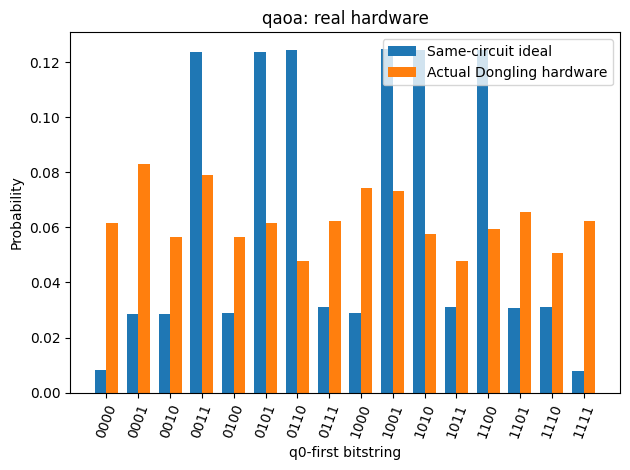

In [8]:
cloud_results = None
if os.environ.get('QB_FINANCE_RUN_CLOUD') == '1':
    session = FinanceCloudSession.from_environment(
        os.environ.get('QB_QUAFU_BACKEND', 'Dongling'),
        journal=ROOT / 'output' / 'finance-hardware' / 'session.json',
        max_tasks=20, shots=1024, max_qubits=6)
    pretty(session.preflight(list(build_finance_cases().values())))
    cloud_results = session.run(case, timeout=300, poll_interval=2)
    assert all(result['hardware_access'] for result in cloud_results.values())
    pretty({name: {k: result[k] for k in ['task_id', 'backend', 'shots', 'raw_counts', 'provider_bit_order']}
            for name, result in cloud_results.items()})
    print('REAL CLOUD FINANCIAL RESULTS:')
    pretty(case.analyze(cloud_results))
elif os.environ.get('QB_FINANCE_REPLAY_HARDWARE') == '1':
    evidence_path = ROOT / 'output' / 'jupyter-notebook' / 'finance' / (case.key + '_hardware_evidence.json')
    existing = json.loads(evidence_path.read_text(encoding='utf-8'))
    cloud_results = existing['hardware_results']
    print('Previously retrieved real hardware counts; no new submission:')
    pretty(analyze_case_evidence(case, cloud_results))
else:
    print('HARDWARE NOT EXECUTED: cloud opt-in disabled. All results above are LOCAL ONLY.')
if cloud_results is not None:
    hardware_acceptance = analyze_case_evidence(case, cloud_results)
    print('Hardware execution COMPLETE; numerical acceptance:', hardware_acceptance['hardware_status'])
    for name, result in cloud_results.items():
        print('Actual task:', result['task_id'], '| backend:', result['backend'], '| shots:', result['shots'])
        print('Raw provider counts:', result['raw_counts'])
        print('Normalized q0-first counts:', result['counts'])
        xs = np.arange(len(result['probabilities']))
        ideal = local_results[name]['ideal_probabilities']
        plt.bar(xs - .18, ideal, width=.36, label='Same-circuit ideal')
        plt.bar(xs + .18, result['probabilities'], width=.36, label='Actual ' + result['backend'] + ' hardware')
        plt.xticks(xs, labels(case.experiments[name].num_qubits), rotation=70)
        plt.xlabel('q0-first bitstring'); plt.ylabel('Probability'); plt.title(name + ': real hardware')
        plt.legend(); plt.tight_layout(); plt.show()

## 7. 本案例的交付证据

        下格保存可复查的输入、参考、中间结果、模拟 counts 和分析结果。
        `hardware_status=not_executed` 不是通过认证；只在取得真实 counts 时写入硬件证据。
        云平台执行硬件电路，本地执行数据加载、优化和金融后处理。

In [9]:
evidence = {
    'case': case.key, 'title': case.title, 'inputs': case.inputs,
    'intermediate': case.intermediate, 'reference': case.reference,
    'local_results': local_results, 'local_analysis': case.analyze(local_results),
    'hardware_status': 'completed' if cloud_results is not None else 'not_executed',
    'hardware_results': cloud_results,
    'hardware_analysis': None if cloud_results is None else case.analyze(cloud_results),
    'acceptance': analyze_case_evidence(case, cloud_results),
    'scope': 'synthetic small research case; not full industry coverage or investment advice',
}
suffix = '_hardware_evidence.json' if cloud_results is not None else '_evidence.json'
destination = ROOT / 'output' / 'jupyter-notebook' / 'finance' / (case.key + suffix)
destination.parent.mkdir(parents=True, exist_ok=True)
destination.write_text(json.dumps(evidence, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('Evidence:', destination.name, '| hardware:', evidence['hardware_status'])

Evidence: allocation_hardware_evidence.json | hardware: completed


## 8. 练习、边界和扩展

        练习：将本地采样从1024增加到4096 shots，保持模型和电路不变，比较误差。
        下面只运行模拟器，**不会增加云端shots或创建新任务**。
        解答思路：比较多个随机种子的误差分布，不能要求每个种子的误差都单调下降。
        采样标准误差一般随 $1/\sqrt N$ 缩小；量子硬件偏差不会由增加 shots 自动消失。

        常见陷阱：把纯 Python 预处理称为硬件能力、把本地 counts 称为真机、按最多出现的位串直接作业务决策、
        忽略负相关符号、混淆风险中性和真实概率、把1024 shots尾部结果当作精确VaR。
        后续可扩展更大模型、真实数据、读出误差缓解、硬件闭环与独立回测；这里没有宣称这些已实现。

In [10]:
more_shots = run_local(case, shots=4096, seed=20261023)
print('LOCAL 4096-shot comparison (no cloud):')
pretty(case.analyze(more_shots))

LOCAL 4096-shot comparison (no cloud):
{
  "feasible_probability": 0.7373046875,
  "optimal_probability": 0.1240234375,
  "expected_penalized_cost": 0.3874809570312501,
  "best_observed_feasible": {
    "bitstring": "1001",
    "selection": [
      1,
      0,
      0,
      1
    ],
    "objective": -0.13,
    "feasible": true,
    "violations": {
      "holdings": 0
    },
    "penalized_cost": -0.13
  },
  "best_observed_gap": 0.0,
  "decision_rule": "best feasible sampled candidate; not necessarily the most frequent string"
}


## 9. 数学与接口参考

        本项目独立实现，未拷贝上游 SDK 源码或教程代码。
        [Qiskit Finance：组合优化](https://qiskit-community.github.io/qiskit-finance/tutorials/01_portfolio_optimization.html)、
        [欧式看涨期权](https://qiskit-community.github.io/qiskit-finance/tutorials/03_european_call_option_pricing.html)、
        [信用风险](https://qiskit-community.github.io/qiskit-finance/tutorials/09_credit_risk_analysis.html)
        提供应用定义参考；本批采用直接采样，而不是复现其 QAE 算法。
        [Quantum Risk Analysis](https://arxiv.org/abs/1806.06893)、
        [Option Pricing using Quantum Computers](https://arxiv.org/abs/1905.02666) 是算法背景，
        论文中的加速结论不适用于本批直接采样实现。
        [QuarkStudio 电路提交接口](https://quarkstudio.readthedocs.io/en/latest/usage/code/transpiler/)
        用于 `quark.Task`、QASM 和 `repeat × 1024` 传输合同。